This code is to check for bifurcations in map using the motion of eigenvalues of Jacobian

# Neimark–Sacker Bifurcation

The Neimark–Sacker bifurcation is the discrete-time analogue of the Hopf bifurcation in continuous systems. It occurs when a pair of complex conjugate eigenvalues of the Jacobian crosses the unit circle in the complex plane, causing a stable fixed point to lose stability and giving rise to an invariant closed curve.

The following two-dimensional discrete-time system is considered:

$$
\begin{aligned}
x_{n+1} = \alpha x_n(1-x_n)-x_ny_n\;\;,\
y_{n+1} = \frac{x_ny_n}{\beta},
\end{aligned}
$$

where $\beta$ is fixed and $\alpha$ is used as the bifurcation parameter.

### Fixed Points

The system has two fixed points:

$$
(x^*,y^*)=(0,0),
$$

and

$$
(x^*,y^*)=\left(\beta,\alpha(1-\beta)-1\right).
$$

### Stability Analysis

The Jacobian matrix of the system is

$$
J=
\begin{pmatrix}
\alpha-2\alpha x-y & -x \\
\dfrac{y}{\beta} & \dfrac{x}{\beta}
\end{pmatrix}.
$$

The eigenvalues of this Jacobian determine the local stability of the fixed point. A fixed point is stable when both eigenvalues satisfy

$$
|\lambda|<1.
$$

Throughout this example, the parameter is fixed at

$$
\beta=0.23,
$$

while $\alpha$ is varied. We analyse the non trivial (non zero) fixed point's stability. At the critical value

$$
\alpha_c=1.85185,
$$

a pair of complex conjugate eigenvalues crosses the unit circle, resulting in a **Neimark–Sacker bifurcation**. Beyond this point, the stable fixed point loses stability and an invariant closed curve emerges in the phase space.



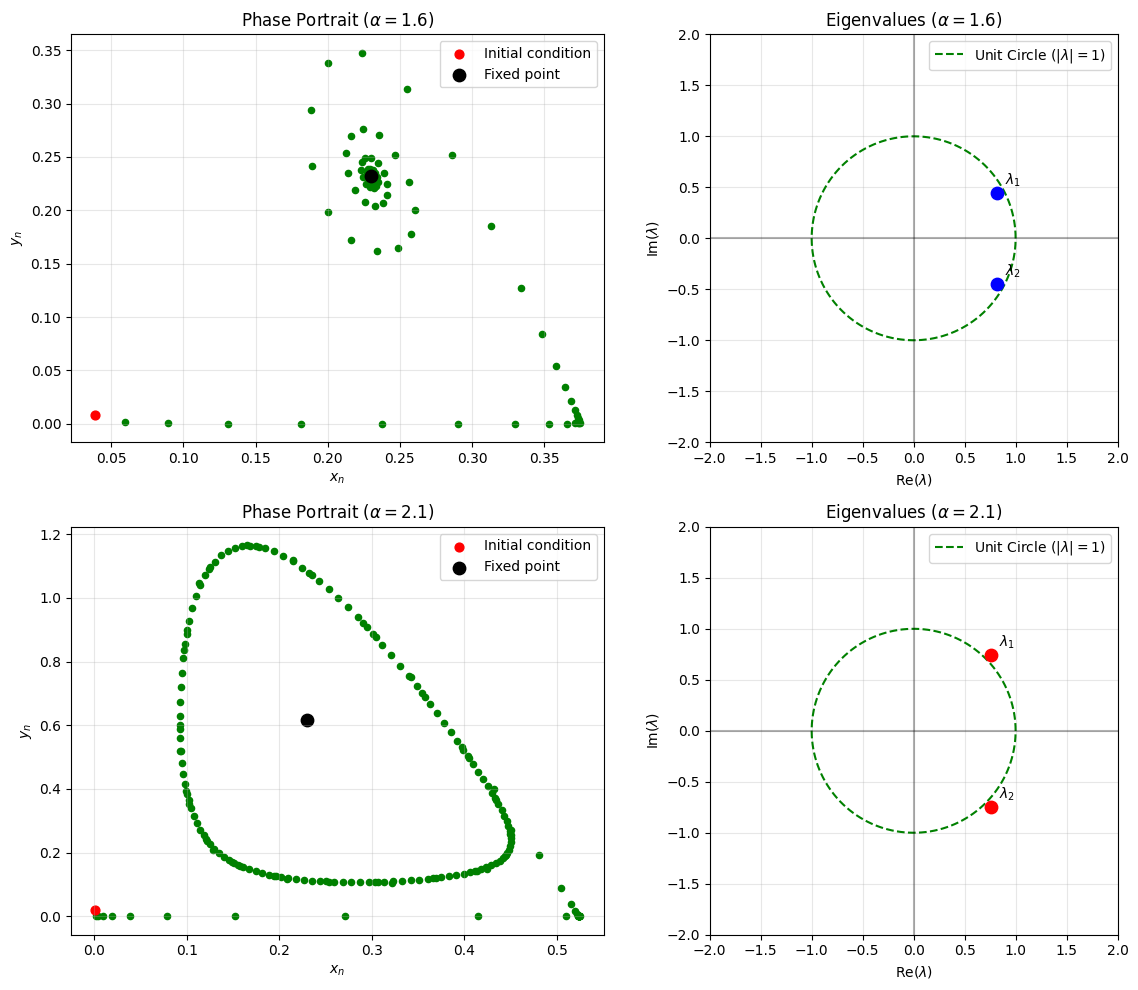

In [11]:
import numpy as np
import matplotlib.pyplot as plt

beta = 0.23

cases = [
    (1.6, (0.039, 0.0078)),
    (2.1, (0.001, 0.02))
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

theta = np.linspace(0, 2*np.pi, 300)

for i, (alpha, ic) in enumerate(cases):


    N = 200

    x = np.zeros(N)
    y = np.zeros(N)

    x[0], y[0] = ic

    for n in range(N-1):
        x[n+1] = alpha*x[n]*(1-x[n]) - x[n]*y[n]
        y[n+1] = x[n]*y[n]/beta

    
    # Phase portrait
    
    ax = axes[i, 0]

    ax.scatter(x, y, color = 'green', s = 20)
    ax.scatter(x[0], y[0], color='red', s=40, label='Initial condition')

    xfp = beta
    yfp = alpha*(1-beta) - 1

    ax.scatter(xfp, yfp,
               color='k',
               marker='o',
               s=80,
               label='Fixed point')

    ax.set_title(rf'Phase Portrait ($\alpha={alpha}$)')
    ax.set_xlabel(r'$x_n$')
    ax.set_ylabel(r'$y_n$')
    ax.grid(alpha=0.3)
    ax.legend()

    
    # Jacobian
    
    J = np.array([
        [alpha - 2*alpha*xfp - yfp, -xfp],
        [yfp/beta, xfp/beta]
    ])

    eigvals = np.linalg.eigvals(J)

    stable = np.max(np.abs(eigvals)) < 1                    #Stability: blue denotes stable and red denotes unstable
    color = 'blue' if stable else 'red'


    # Eigenvalues
    
    ax = axes[i, 1]

    ax.plot(np.cos(theta), np.sin(theta),
            'g--', lw=1.5,
            label=r'Unit Circle ($|\lambda|=1$)')

    ax.axhline(0, color='k', alpha=0.3)
    ax.axvline(0, color='k', alpha=0.3)

    ax.scatter(eigvals.real,
               eigvals.imag,
               color=color,
               s=80,
               zorder=5)

    for j, lam in enumerate(eigvals):
        ax.text(lam.real+0.08,
                lam.imag+0.08,
                rf'$\lambda_{j+1}$',
                fontsize=10)

    ax.set_title(rf'Eigenvalues ($\alpha={alpha}$)')
    ax.set_xlabel(r'Re($\lambda$)')
    ax.set_ylabel(r'Im($\lambda$)')
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect('equal')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()